In [54]:
import importlib
import os
from pathlib import Path
import site
import subprocess
import sys
import sysconfig
import json

COURSE_SOURCE_REF = "v0.2.2"
COURSE_REPOSITORY = "https://gitlab.unimelb.edu.au/dream/dream-gym.git"
COLAB_CHECKOUT = Path("/content/dream-gym-current")
IS_COLAB = "google.colab" in sys.modules
package_was_loaded = any(
    name == "dreamgym" or name.startswith("dreamgym.")
    for name in sys.modules
)
setup_diagnostic = None

if IS_COLAB:
    if package_was_loaded:
        setup_diagnostic = "restart the Colab runtime before continuing"
    else:
        try:
            if COLAB_CHECKOUT.exists():
                if not (COLAB_CHECKOUT / ".git").is_dir():
                    raise RuntimeError("unverifiable checkout")
                origin = subprocess.run(
                    ("git", "-C", str(COLAB_CHECKOUT), "remote", "get-url", "origin"),
                    capture_output=True, text=True, check=True,
                ).stdout.strip()
                if origin != COURSE_REPOSITORY:
                    raise RuntimeError("unexpected checkout origin")
                status = subprocess.run(
                    ("git", "-C", str(COLAB_CHECKOUT), "status", "--porcelain"),
                    capture_output=True, text=True, check=True,
                ).stdout.strip()
                if status:
                    raise RuntimeError("checkout has local changes")
                subprocess.run(
                    ("git", "-C", str(COLAB_CHECKOUT), "fetch", "--depth", "1", "origin", COURSE_SOURCE_REF),
                    capture_output=True, text=True, check=True,
                )
                subprocess.run(
                    ("git", "-C", str(COLAB_CHECKOUT), "checkout", "--detach", "FETCH_HEAD"),
                    capture_output=True, text=True, check=True,
                )
            else:
                subprocess.run(
                    ("git", "clone", "--branch", COURSE_SOURCE_REF, "--single-branch", COURSE_REPOSITORY, str(COLAB_CHECKOUT)),
                    capture_output=True, text=True, check=True,
                )
            subprocess.run(
                (sys.executable, "-m", "pip", "install", "-e", "."),
                cwd=COLAB_CHECKOUT, capture_output=True, text=True, check=True,
            )
            site.addsitedir(sysconfig.get_paths()["purelib"])
            os.chdir(COLAB_CHECKOUT)
            importlib.invalidate_caches()
        except (OSError, RuntimeError, subprocess.CalledProcessError):
            setup_diagnostic = "notebook setup failed"

if setup_diagnostic is not None:
    print(setup_diagnostic)

In [34]:
if setup_diagnostic is not None:
    raise RuntimeError(
        f"Notebook setup did not complete: {setup_diagnostic}"
    )


## Execution mode

The following code cell defines the two executions modes of the notebooks:
* `smoke` is a quick run to check everything is working, which in the case of this notebook is producing a small animation.
* `full` is the run that produces everything, which in the case of this notebook produces a full length animation.

Keep `RUN_MODE = "smoke"` while developing: it runs every stage with a small deterministic prefix so you can interpret the workflow quickly. Choose `full` for the longer reference sample after the notebook is working.

Runtime artifacts stay below `notebook_outputs/performance-metrics-and-uncertainty/`.

| Property | Units | Allowed values | Inheritance/default | Why it is present |
|---|---|---|---|---|
| `nominal_steps` | steps | `smoke`: `80`; `full`: `400` | Selected by `RUN_MODE`; no inheritance | Bounds the worked single-policy rollout |
| `sweep_samples` | rollouts | `smoke`: `8`; `full`: `64` | Selected by `RUN_MODE`; no inheritance | Uses a small deterministic prefix for smoke and the complete reference sample in full mode |
| `sweep_steps` | steps | `smoke`: `80`; `full`: `400` | Selected by `RUN_MODE`; no inheritance | Bounds every uncertainty-sweep rollout |

In [35]:
RUN_MODE = "full"
if RUN_MODE not in {"smoke", "full"}:
    raise ValueError("RUN_MODE must be 'smoke' or 'full'")
OUTPUT_ROOT = Path("notebook_outputs") / "performance-metrics-and-uncertainty"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
MODE = {
    "smoke": {"nominal_steps": 80, "sweep_samples": 8, "sweep_steps": 80},
    "full": {"nominal_steps": 400, "sweep_samples": 64, "sweep_steps": 400},
}[RUN_MODE]


## Imports

In [36]:
import dreamgym
dreamgym_source = Path(dreamgym.__file__).resolve()
if IS_COLAB and not dreamgym_source.is_relative_to(COLAB_CHECKOUT.resolve()):
    raise RuntimeError("Dream Gym resolved outside the selected Colab checkout")

from copy import deepcopy

import gymnasium
import matplotlib.pyplot as plt
import numpy as np
from dreamgym.envs import Road
from dreamgym.evaluation import (
    MetricSet,
    PerformanceMetric,
    PerformanceMetricResults,
    PolicySpec,
    save_metric_tables,
)
from dreamgym.evaluation.autonomous_driving import (
    AutonomousDrivingEvaluationConfig,
    InitialStateValueParameter,
    UncertaintySweep,
    UniformMultiplierParameter,
    evaluate_policies_over_sweep,
    metric_by_name,
    rerun_sweep_rollout,
    simulate_policy,
)
from dreamgym.policies.autonomous_driving import PIDPolicyForAutonomousDriving
from dreamgym.visualization import (
    plot_metric_histograms,
    save_performance_metric_plots,
)
from dreamgym.visualization.autonomous_driving import (
    plot_simulation_results,
    save_figure,
)


## Setup Road, Observations, and the Environment

To be able to run the performance metrics and uncertainty sweeps we define, the following code cell specifies the details of a Road, observations, and environment that are used throughout the notebook.

For full details, see the docs in the Gymnasium's repository
* [Road schema](https://gitlab.unimelb.edu.au/dream/dream-gym/-/blob/main/docs/road.md?ref_type=heads)
* [Observation schema](https://gitlab.unimelb.edu.au/dream/dream-gym/-/blob/main/docs/observations.md?ref_type=heads)
* [Public environment configuration reference](https://gitlab.unimelb.edu.au/dream/dream-gym/-/blob/main/docs/public_environment_v1_migration.md?ref_type=heads).

In [37]:
METRICS_OBSERVATIONS = (
    "target_line_curvature_per_m",
    "target_line_lookahead_curvatures_per_m",
    "lateral_error_from_target_line_m",
    "ground_truth_body_longitudinal_velocity_mps",
    "ground_truth_body_lateral_velocity_mps",
)
METRICS_NOMINAL_SEED = 20260810
METRICS_ROAD_SPEC = {
    "elements": [
        {
            "geometry": {"type": "straight", "length_m": 200.0},
            "speed_limit_kph": 60.0,
            "cross_section_width_interpolation": "constant",
            "lanes": {
                "reference_line_role": "lane_center",
                "reference_lane": {
                    "width_m": {"start": 3.6, "end": 3.6},
                    "surface": "tarmac",
                },
            },
        },
        {
            "geometry": {
                "type": "circular_arc",
                "curvature_per_m": 1.0 / 300.0,
                "sweep_angle_deg": 45.0,
            },
        },
        {"geometry": {"type": "straight", "length_m": 300.0}},
        {
            "geometry": {
                "type": "circular_arc",
                "curvature_per_m": -1.0 / 300.0,
                "sweep_angle_deg": 45.0,
            },
        },
        {"geometry": {"type": "straight", "length_m": 700.0}},
    ]
}
metrics_road = Road(road_spec=METRICS_ROAD_SPEC)
METRICS_OBSERVATION_CONFIG = {
    "target_line_curvature_per_m": {
        "destination": "observation",
        "scaling_factor": 1.0,
    },
    "target_line_lookahead": {
        "maximum_distance_m": 60.0,
        "sample_count": 1,
        "curvatures_per_m": {
            "destination": "observation",
            "scaling_factor": 1.0,
        },
    },
    "lateral_error_from_target_line_m": {
        "destination": "observation",
        "scaling_factor": 1.0,
    },
    "ground_truth_body_longitudinal_velocity_mps": {
        "destination": "observation",
        "scaling_factor": 1.0,
    },
    "ground_truth_body_lateral_velocity_mps": {
        "destination": "observation",
        "scaling_factor": 1.0,
    },
}
METRICS_ENVIRONMENT_KWARGS = {
    "render_mode": None,
    "road_spec": METRICS_ROAD_SPEC,
    "integration_config": {
        "method": "rk4",
        "environment_step_duration_s": 0.05,
        "substep_count": 1,
    },
    "termination_config": {
        "planar_speed_bounds_mps": {
            "lower": 0.0,
            "upper": 200.0 / 3.6,
        },
        "absolute_lateral_error_from_target_line_upper_bound_m": 20.0,
    },
    "initial_state_config": {
        "bounds": {
            "world_pose": {
                "x_m": {"lower": 0.0, "upper": 0.0},
                "y_m": {"lower": 0.0, "upper": 0.0},
                "heading_rad": {"lower": 0.0, "upper": 0.0},
            },
            "body_motion": {
                "longitudinal_velocity_mps": {
                    "lower": 60.0 / 3.6,
                    "upper": 60.0 / 3.6,
                },
                "lateral_velocity_mps": {"lower": 0.0, "upper": 0.0},
                "yaw_rate_rad_per_s": {"lower": 0.0, "upper": 0.0},
            },
            "front_wheel_steering_angle_rad": {
                "lower": 0.0,
                "upper": 0.0,
            },
        }
    },
    "observation_config": METRICS_OBSERVATION_CONFIG,
    "target_line_config": {"mode": "reference_line"},
    "internal_policy_config": {
        "lane_keeping": {"enabled": False},
        "cruise_control": {"enabled": False},
        "action_interface": "full",
    },
    "observation_format": "dict",
}


## 1. Define the metrics

This section defines a set of performance metrics using both built-in metrics and a custom metric.

For full details, see the [performance metrics documentation](https://gitlab.unimelb.edu.au/dream/dream-gym/-/blob/main/docs/performance_metrics.md?ref_type=heads) in the Gymnasium's repository.

In [38]:
BUILT_IN_METRIC_NAMES = (
    "mean_abs_lateral_error_m",
    "mean_abs_speed_error_to_recommended_kph",

    # additional client requirements
    "final_progress_m"
)
built_in_metrics = tuple(
    metric_by_name(name) for name in BUILT_IN_METRIC_NAMES
)


### Custom metric

This cell defines a custom metric using the Gymnasium's `PerformanceMetric` class.

In [ ]:
LATERAL_TOLERANCE_M = 0.75
SPEED_TOLERANCE_KPH = 1.0
SPEED_TOLERANCE_MPS = SPEED_TOLERANCE_KPH / 3.6

def _get_finite_series(time_series, field_name):
    return np.asarray(
        time_series[field_name],
        dtype=np.float64,
    ).reshape(-1)


def _get_sample_period(time_series):
    time_s = _get_finite_series(
        time_series,
        "time_in_seconds",
    )

    time_s = time_s[np.isfinite(time_s)]

    if time_s.size < 2:
        return float("nan")

    time_differences_s = np.diff(time_s)
    time_differences_s = time_differences_s[
        np.isfinite(time_differences_s)
        & (time_differences_s > 0.0)
    ]

    if time_differences_s.size == 0:
        return float("nan")

    return float(np.median(time_differences_s))


def cumulative_overspeed_duration(time_series):
    speed_mps = _get_finite_series(
        time_series,
        "vx",
    )

    recommended_speed_mps = _get_finite_series(
        time_series,
        "recommended_speed_at_closest_point",
    )

    valid = (
        np.isfinite(speed_mps)
        & np.isfinite(recommended_speed_mps)
    )

    if not np.any(valid):
        return float("nan")

    sample_period_s = _get_sample_period(time_series)

    if not np.isfinite(sample_period_s):
        return float("nan")

    overspeed = (
        speed_mps[valid]
        > recommended_speed_mps[valid] + SPEED_TOLERANCE_MPS
    )

    return float(
        sample_period_s * np.sum(overspeed)
    )


cumulative_overspeed_duration_metric = PerformanceMetric(
    name="cumulative_overspeed_duration_s",
    display_name="Cumulative overspeed duration",
    unit="s",
    direction="smaller",
    requirement_group="speed",
    required_fields=(
        "time_in_seconds",
        "vx",
        "recommended_speed_at_closest_point",
    ),
    equation=(
        "Ts * sum(v_k > v_k_star + 1 km/h)"
    ),
    description=(
        "Total time spent more than 1 km/h above the "
        "recommended road speed."
    ),
    justification=(
        "Measures how long the vehicle violates the recommended "
        "speed requirement while ignoring very small numerical "
        "differences within the selected 1 km/h tolerance."
    ),
    function=cumulative_overspeed_duration,
    primary_aggregate="mean",
)


def maximum_overspeed(time_series):
    speed_mps = _get_finite_series(
        time_series,
        "vx",
    )

    recommended_speed_mps = _get_finite_series(
        time_series,
        "recommended_speed_at_closest_point",
    )

    valid = (
        np.isfinite(speed_mps)
        & np.isfinite(recommended_speed_mps)
    )

    if not np.any(valid):
        return float("nan")

    overspeed_kph = (
        speed_mps[valid]
        - recommended_speed_mps[valid]
    ) * 3.6

    return float(
        np.max(np.maximum(overspeed_kph, 0.0))
    )


maximum_overspeed_metric = PerformanceMetric(
    name="maximum_overspeed_kph",
    display_name="Maximum overspeed",
    unit="km/h",
    direction="smaller",
    requirement_group="speed",
    required_fields=(
        "vx",
        "recommended_speed_at_closest_point",
    ),
    equation=(
        "max([v_k - v_k_star]_+)"
    ),
    description=(
        "Largest amount by which the vehicle exceeds the "
        "recommended speed."
    ),
    justification=(
        "Complements overspeed duration by measuring the severity "
        "of the worst overspeed event."
    ),
    function=maximum_overspeed,
    primary_aggregate="mean",
)


# Requirement 3: Smooth acceleration and deceleration

def rms_longitudinal_jerk(time_series):
    time_s = _get_finite_series(
        time_series,
        "time_in_seconds",
    )

    speed_mps = _get_finite_series(
        time_series,
        "vx",
    )

    if time_s.size != speed_mps.size:
        raise ValueError("time and speed series must have equal length")

    if speed_mps.size < 3:
        return float("nan")

    valid = np.isfinite(time_s) & np.isfinite(speed_mps)

    if np.count_nonzero(valid) < 3:
        return float("nan")

    time_s = time_s[valid]
    speed_mps = speed_mps[valid]

    dt = np.diff(time_s)

    if np.any(dt <= 0.0):
        return float("nan")

    acceleration_mps2 = np.diff(speed_mps) / dt

    acceleration_time_s = time_s[1:]
    acceleration_dt = np.diff(acceleration_time_s)

    jerk_mps3 = (
        np.diff(acceleration_mps2)
        / acceleration_dt
    )

    return float(
        np.sqrt(np.mean(jerk_mps3 ** 2))
    )


rms_longitudinal_jerk_metric = PerformanceMetric(
    name="rms_longitudinal_jerk_mps3",
    display_name="RMS longitudinal jerk",
    unit="m/s^3",
    direction="smaller",
    requirement_group="smoothness",
    required_fields=("time_in_seconds", "vx"),
    equation="RMS of the time derivative of longitudinal acceleration",
    description="RMS rate of change of longitudinal acceleration.",
    justification="Measures longitudinal acceleration and deceleration smoothness.",
    function=rms_longitudinal_jerk,
    primary_aggregate="mean",
)


# Requirement 4: Smooth lane keeping
def rms_steering_request_rate(time_series):
    time_s = _get_finite_series(
        time_series,
        "time_in_seconds",
    )

    steering_request_rad = _get_finite_series(
        time_series,
        "delta_request",
    )

    if time_s.size != steering_request_rad.size:
        raise ValueError(
            "time and steering series must have equal length"
        )

    valid = (
        np.isfinite(time_s)
        & np.isfinite(steering_request_rad)
    )

    if np.count_nonzero(valid) < 2:
        return float("nan")

    time_s = time_s[valid]
    steering_request_rad = steering_request_rad[valid]

    dt = np.diff(time_s)

    if np.any(dt <= 0.0):
        return float("nan")

    steering_rate_rad_per_s = (
        np.diff(steering_request_rad) / dt
    )

    return float(
        np.sqrt(
            np.mean(steering_rate_rad_per_s ** 2)
        )
    )


rms_steering_request_rate_metric = PerformanceMetric(
    name="rms_steering_request_rate_rad_per_s",
    display_name="RMS steering request rate",
    unit="rad/s",
    direction="smaller",
    requirement_group="lane_keeping",
    required_fields=(
        "time_in_seconds",
        "delta_request",
    ),
    equation=(
        "sqrt(mean(((delta_k - delta_(k-1)) / Ts)^2))"
    ),
    description=(
        "Root-mean-square rate of change of the requested "
        "front-wheel steering angle."
    ),
    justification=(
        "Rapid steering changes indicate less smooth lane-keeping. "
        "This metric is interpreted together with lateral error so "
        "that simply avoiding steering cannot appear successful."
    ),
    function=rms_steering_request_rate,
    primary_aggregate="mean",
)

def fraction_outside_lateral_tolerance(time_series):
    lateral_error_m = np.asarray(
        time_series["lateral_error_from_target_line"],
        dtype=np.float64,
    ).reshape(-1)
    finite_lateral_error_m = lateral_error_m[np.isfinite(lateral_error_m)]
    if finite_lateral_error_m.size == 0:
        return float("nan")
    return float(
        np.mean(np.abs(finite_lateral_error_m) > LATERAL_TOLERANCE_M)
    )


fraction_outside_lateral_tolerance_metric = PerformanceMetric(
    name="fraction_outside_lateral_tolerance",
    display_name="Fraction outside lateral tolerance",
    unit="fraction",
    direction="smaller",
    requirement_group="lane_keeping",
    required_fields=("lateral_error_from_target_line",),
    equation=(
        "count(abs(finite lateral_error_from_target_line) > "
        "lateral_tolerance_m) / count(finite samples)"
    ),
    description=(
        "Fraction of finite rollout samples beyond the editable "
        "absolute lateral-error tolerance."
    ),
    justification=(
        "Separates persistent lane-margin excursions from the "
        "average-error magnitude."
    ),
    function=fraction_outside_lateral_tolerance,
    primary_aggregate="mean",
)


### Put the metrics together in a set

This cell combines the performane metrics defined above (both the built-in and the custom metrics) into a set that will be used during evaluation.

In [40]:
metrics = MetricSet(
    (*built_in_metrics, 
    fraction_outside_lateral_tolerance_metric,

    #custom
    cumulative_overspeed_duration_metric,
    maximum_overspeed_metric,
    rms_longitudinal_jerk_metric,
    rms_steering_request_rate_metric,)
)

metric_summary_rows = [
    {
        "name": metric.name,
        "unit": metric.unit,
        "direction": metric.direction.value,
        "required_fields": metric.required_fields,
        "primary_aggregate": metric.primary_aggregate,
    }
    for metric in metrics
]
for metric_summary_row in metric_summary_rows:
    print(metric_summary_row)


{'name': 'mean_abs_lateral_error_m', 'unit': 'm', 'direction': 'smaller', 'required_fields': ('lateral_error_from_target_line',), 'primary_aggregate': 'mean'}
{'name': 'mean_abs_speed_error_to_recommended_kph', 'unit': 'km/h', 'direction': 'smaller', 'required_fields': ('vx', 'recommended_speed_at_closest_point'), 'primary_aggregate': 'mean'}
{'name': 'final_progress_m', 'unit': 'm', 'direction': 'bigger', 'required_fields': ('reference_line_progress_at_closest_point',), 'primary_aggregate': 'mean'}
{'name': 'fraction_outside_lateral_tolerance', 'unit': 'fraction', 'direction': 'smaller', 'required_fields': ('lateral_error_from_target_line',), 'primary_aggregate': 'mean'}
{'name': 'cumulative_overspeed_duration_s', 'unit': 's', 'direction': 'smaller', 'required_fields': ('time_in_seconds', 'vx', 'recommended_speed_at_closest_point'), 'primary_aggregate': 'mean'}
{'name': 'maximum_overspeed_kph', 'unit': 'km/h', 'direction': 'smaller', 'required_fields': ('vx', 'recommended_speed_at_clo

### What you should see

The previous cell should display one rows per metric. Hence, as the notebook is supplied, this shouldl be two built-in metrics followed by the custom metric. Double check the units, direction, required fields, and primary aggregate before interpreting any values.

### Simulate a roll-out and compute the metrics

The following cell performs one simulation of a car driving along the road, and then evaluated the metrics set from the simulation time series results.

In [41]:
nominal_environment = gymnasium.make(
    "dreamgym/autonomous_driving_env",
    **METRICS_ENVIRONMENT_KWARGS,
)
try:
    nominal_steering_limit_rad = nominal_environment.unwrapped.car.normalized_config[
        "steering"
    ]["requested_front_wheel_angle_magnitude_limit_rad"]
    nominal_policy = PIDPolicyForAutonomousDriving(
        delta_request_max=nominal_steering_limit_rad
    )
    nominal_time_series = simulate_policy(
        nominal_environment,
        MODE["nominal_steps"],
        nominal_policy,
        seed=METRICS_NOMINAL_SEED,
        policy_seed=METRICS_NOMINAL_SEED,
        should_save_look_ahead_results=False,
        should_save_observations=False,
    )
finally:
    nominal_environment.close()

nominal_finite_rewards = np.asarray(
    nominal_time_series["reward"],
    dtype=np.float64,
)
nominal_finite_rewards = nominal_finite_rewards[
    np.isfinite(nominal_finite_rewards)
]
if nominal_finite_rewards.size == 0:
    raise RuntimeError("the nominal rollout did not record a finite Gym reward")
nominal_reward_value = float(np.mean(nominal_finite_rewards))
nominal_metric_rows = [
    {
        "name": metric.name,
        "display_name": metric.display_name,
        "value": float(metric.function(nominal_time_series)),
        "unit": metric.unit,
        "direction": metric.direction.value,
    }
    for metric in metrics
]
print("Nominal Gym reward:", nominal_reward_value)
print("Nominal metric values:")
for metric_row in nominal_metric_rows:
    print(metric_row)


Nominal Gym reward: 0.0
Nominal metric values:
{'name': 'mean_abs_lateral_error_m', 'display_name': 'Mean absolute lateral error', 'value': 0.33122886773683663, 'unit': 'm', 'direction': 'smaller'}
{'name': 'mean_abs_speed_error_to_recommended_kph', 'display_name': 'Mean absolute recommended-speed error', 'value': 0.45652001587827307, 'unit': 'km/h', 'direction': 'smaller'}
{'name': 'final_progress_m', 'display_name': 'Final progress', 'value': 330.302001953125, 'unit': 'm', 'direction': 'bigger'}
{'name': 'fraction_outside_lateral_tolerance', 'display_name': 'Fraction outside lateral tolerance', 'value': 0.18703241895261846, 'unit': 'fraction', 'direction': 'smaller'}
{'name': 'cumulative_overspeed_duration_s', 'display_name': 'Cumulative overspeed duration', 'value': 0.0, 'unit': 's', 'direction': 'smaller'}
{'name': 'maximum_overspeed_kph', 'display_name': 'Maximum overspeed', 'value': 0.0, 'unit': 'km/h', 'direction': 'smaller'}
{'name': 'rms_longitudinal_jerk_mps3', 'display_name'

## 2. Evaluate a bounded uncertainty block

This section runs a sweep over uncertainties.

As the notebook is provided, the uncertainty block varies only vehicle mass and initial lateral position. When you get to evaluating your actual policies (for PID, RL, and MPC), you should make your own choices about what uncertainties to vary and update the code accordingly.

### Conventions and definitions

Smoke's eight cases are the prefix of the same seeded 64-case full sample. Aggregate metric values are conditional on unflagged rollouts. Requested, contributing, and flagged counts remain visible; a flag records termination or truncation and is not automatically synonymous with controller failure until its cause is inspected. See the [performance metrics documentation](https://gitlab.unimelb.edu.au/dream/dream-gym/-/blob/main/docs/performance_metrics.md?ref_type=heads) for more details.

| Property | Units | Allowed values / range | Default / inheritance | Why this notebook uses it |
|---|---|---|---|---|
| `METRICS_SWEEP_ENVIRONMENT_KWARGS.bicycle_model_config` | public vehicle configuration | Deep copy of the registered environment value | Nominal mapping omits this registered default | Supplies the mass leaf before the multiplier is applied |
| `METRICS_SWEEP_ENVIRONMENT_KWARGS.road_spec` | Road specification | The fixed nominal Road specification | Deep-copied from `METRICS_ENVIRONMENT_KWARGS` | Holds Road geometry and speed recommendations constant |
| `METRICS_SWEEP_ENVIRONMENT_KWARGS.observation_config.fixed_noise_seed` | unitless | Exactly `20260810` | Explicit fixed seed | Keeps the zero-noise observation stream reproducible |
| `METRICS_SWEEP_ENVIRONMENT_KWARGS.observation_config.lateral_error_from_target_line_m.noise_standard_deviation_m` | m | Exactly `0.0` | Public default is zero | Keeps observation noise fixed rather than sampled |
| `mass_multiplier` | ratio | 0.95 to 1.05 | Multiplies copied registered mass | Represents bounded plant-mass uncertainty |
| `initial_world_position_y_m` | m | -0.25 to 0.25 | Fixes both initial-state bounds to one sampled value | Represents bounded starting lateral displacement |
| `policy_seed` | unitless | Public deterministic fallback | Absent from each sample | Keeps policy lifecycle seeding fixed |
| `rollout_seed` | unitless | Public deterministic fallback `0` | Absent from each sample | Keeps environment reset seeding fixed |
| `metrics_sweep.samples` | rollouts | Smoke 8 and full 64 | Selected by `MODE` | Keeps smoke as a strict prefix of full |
| `metrics_sweep.seed` | unitless | Exactly 20260810 | No implicit seed | Fixes Monte Carlo sample ordering |
| `metrics_evaluation_config.n_steps` | steps | Smoke 80 and full 400 | Selected by `MODE` | Bounds each rollout |
| `metrics_evaluation_config.base_env_kwargs` | environment configuration | Fixed setup mapping in code | No hidden merge beyond Gymnasium registration | Carries the fixed Road, noise, and registered vehicle configuration |
| `metrics_evaluation_config.include_look_ahead_results` | unitless | `False` | Public default is false | Avoids retaining unused bulk lookahead arrays |
| `metrics_evaluation_config.include_observations` | unitless | `False` | Public default is false | Avoids retaining unused bulk observation arrays |
| `metrics_policy_spec.name` | unitless | `simple_proportional_baseline` | Must be unique within the evaluation | Labels the teaching baseline |
| `include_per_rollout_metrics` | unitless | `True` | Evaluator default is false | Retains scalar case rows for filtering and rerun selection |

### Specifiy the uncertainty sweeps

In [42]:
METRICS_UNCERTAINTY_PARAMETERS = (
    UniformMultiplierParameter(
        name="mass_multiplier",
        path=("bicycle_model_config", "mass_properties", "mass_kg"),
        low=0.95,
        high=1.05,
    ),
    InitialStateValueParameter(
        name="initial_world_position_y_m",
        path=("world_pose", "y_m"),
        low=-0.25,
        high=0.25,
    ),
)
metrics_sweep = UncertaintySweep.monte_carlo(
    METRICS_UNCERTAINTY_PARAMETERS,
    samples=MODE["sweep_samples"],
    seed=20260810,
)


### Built the environment to be used for the uncertainty sweeps

In [43]:
METRICS_SWEEP_ENVIRONMENT_KWARGS = deepcopy(METRICS_ENVIRONMENT_KWARGS)
METRICS_SWEEP_ENVIRONMENT_KWARGS["bicycle_model_config"] = deepcopy(
    gymnasium.spec("dreamgym/autonomous_driving_env").kwargs["bicycle_model_config"]
)
METRICS_SWEEP_ENVIRONMENT_KWARGS["observation_config"][
    "lateral_error_from_target_line_m"
]["noise_standard_deviation_m"] = 0.0
METRICS_SWEEP_ENVIRONMENT_KWARGS["observation_config"][
    "fixed_noise_seed"
] = METRICS_NOMINAL_SEED

metrics_evaluation_config = AutonomousDrivingEvaluationConfig(
    n_steps=MODE["sweep_steps"],
    base_env_kwargs=METRICS_SWEEP_ENVIRONMENT_KWARGS,
    include_look_ahead_results=False,
    include_observations=False,
)
metrics_policy_spec = PolicySpec(
    name="simple_proportional_baseline",
    policy=nominal_policy,
)


### Run the uncertainty sweep computations

In [44]:
metrics_results = evaluate_policies_over_sweep(
    policies=(metrics_policy_spec,),
    config=metrics_evaluation_config,
    metrics=metrics,
    sweep=metrics_sweep,
    include_per_rollout_metrics=True,
)


### Display the results

In [45]:
if metrics_results.per_rollout_metric_rows is None:
    raise RuntimeError("per-rollout metrics are required for this workflow")
summary_rows = []
for aggregate_row in metrics_results.aggregate_rows:
    rollout_count = int(aggregate_row["rollout_count"])
    flagged_rollout_count = int(aggregate_row["flagged_rollout_count"])
    summary_row = {
        "policy_name": aggregate_row["policy_name"],
        "rollout_count": rollout_count,
        "metric_rollout_count": int(aggregate_row["metric_rollout_count"]),
        "flagged_rollout_count": flagged_rollout_count,
        "flagged_rate": (
            flagged_rollout_count / rollout_count
            if rollout_count
            else float("nan")
        ),
    }
    summary_row.update({
        metric.name + "__primary": aggregate_row[metric.name + "__primary"]
        for metric in metrics
    })
    summary_rows.append(summary_row)

print("Requested, contributing, and flagged rollout counts:")
print("Aggregate metric values are conditional on unflagged rollouts.")
print(
    "Reminder: flagged is not automatically synonymous with controller "
    "failure; inspect its cause."
)
for summary_row in summary_rows:
    print(summary_row)


Requested, contributing, and flagged rollout counts:
Aggregate metric values are conditional on unflagged rollouts.
Reminder: flagged is not automatically synonymous with controller failure; inspect its cause.
{'policy_name': 'simple_proportional_baseline', 'rollout_count': 64, 'metric_rollout_count': 64, 'flagged_rollout_count': 0, 'flagged_rate': 0.0, 'mean_abs_lateral_error_m__primary': 0.45579186936948063, 'mean_abs_speed_error_to_recommended_kph__primary': 0.47236262241801125, 'final_progress_m__primary': 330.1156487464905, 'fraction_outside_lateral_tolerance__primary': 0.20300810473815462, 'cumulative_overspeed_duration_s__primary': 0.0, 'maximum_overspeed_kph__primary': 0.0, 'rms_longitudinal_jerk_mps3__primary': 0.04029731439488489, 'rms_steering_request_rate_rad_per_s__primary': 0.006419548706577974}


### Plot a histogram of the results for one performance metric

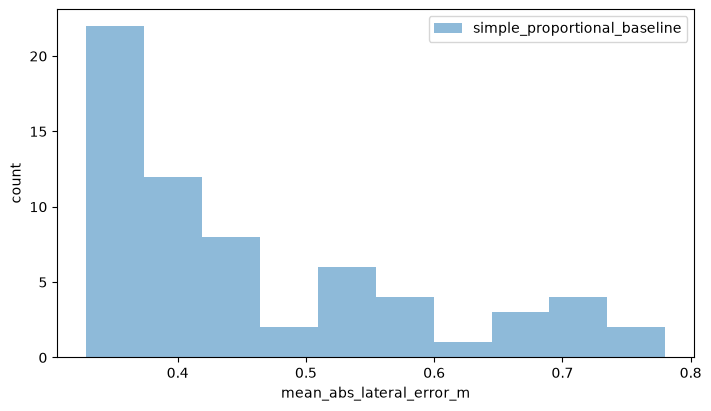

In [46]:
unflagged_metric_rows = [
    row
    for row in metrics_results.per_rollout_metric_rows
    if not (
        bool(row.get("terminated", False))
        or bool(row.get("truncated", False))
    )
]
histogram_results = PerformanceMetricResults(
    aggregate_rows=metrics_results.aggregate_rows,
    rollout_index_rows=metrics_results.rollout_index_rows,
    per_rollout_metric_rows=unflagged_metric_rows,
)
histogram_figure_numbers_before = set(plt.get_fignums())
try:
    histogram_figure = plot_metric_histograms(
        histogram_results,
        BUILT_IN_METRIC_NAMES[0],
    )
    plt.show()
finally:
    for figure_number in (
        set(plt.get_fignums()) - histogram_figure_numbers_before
    ):
        plt.close(figure_number)


## 3. Inspect a concerning case

This section digs deeper in the detail of what happen during a roll-out that produce a poor-performance value for one of the performance metrics.

### Identify the concerning case

This cell finds the rollout index of the concerning case.

In [47]:
CONCERNING_METRIC_NAME = BUILT_IN_METRIC_NAMES[0]
metric_rows = list(metrics_results.per_rollout_metric_rows or ())
if not metric_rows:
    raise RuntimeError("at least one per-rollout metric row is required")
flagged_metric_rows = sorted(
    (
        row
        for row in metric_rows
        if bool(row.get("terminated", False))
        or bool(row.get("truncated", False))
    ),
    key=lambda row: (int(row["rollout_index"]), str(row["policy_name"])),
)
if flagged_metric_rows:
    concerning_metric_row = flagged_metric_rows[0]
else:
    finite_concerning_rows = []
    for row in metric_rows:
        try:
            concerning_value = float(
                row.get(CONCERNING_METRIC_NAME, float("nan"))
            )
        except (TypeError, ValueError):
            concerning_value = float("nan")
        if np.isfinite(concerning_value):
            finite_concerning_rows.append((concerning_value, row))
    if not finite_concerning_rows:
        raise RuntimeError("no finite selected metric is available for rerun")
    concerning_metric_row = max(
        finite_concerning_rows,
        key=lambda item: (item[0], -int(item[1]["rollout_index"])),
    )[1]

concerning_identity = (
    str(concerning_metric_row["policy_name"]),
    int(concerning_metric_row["rollout_index"]),
)
matching_rollout_index_rows = [
    row
    for row in metrics_results.rollout_index_rows
    if (str(row["policy_name"]), int(row["rollout_index"]))
    == concerning_identity
]
if len(matching_rollout_index_rows) != 1:
    raise RuntimeError(
        "concerning rollout identity must match exactly one index row"
    )
concerning_rollout_index_row = matching_rollout_index_rows[0]


### Rerun the rollout for the concerning case

This rerun is necessary because the original full uncertainty sweep does not save the simulation time series for every rollout (that would be an unreasonable amount of data to save).

In [48]:
concerning_time_series = rerun_sweep_rollout(
    metrics_policy_spec,
    metrics_evaluation_config,
    metrics_sweep,
    concerning_rollout_index_row,
)


###Plot the time-series of the concerning rollout

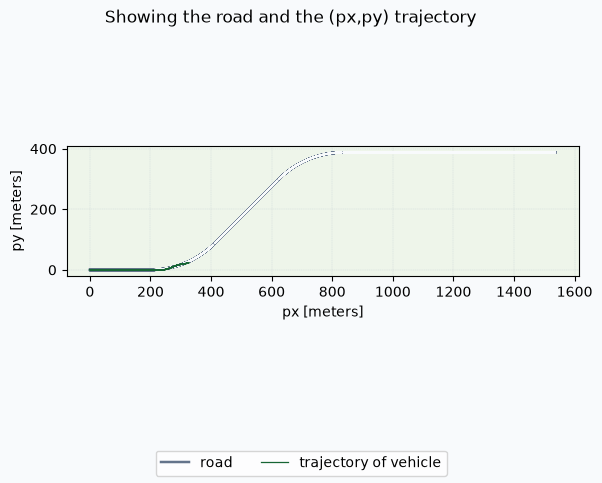

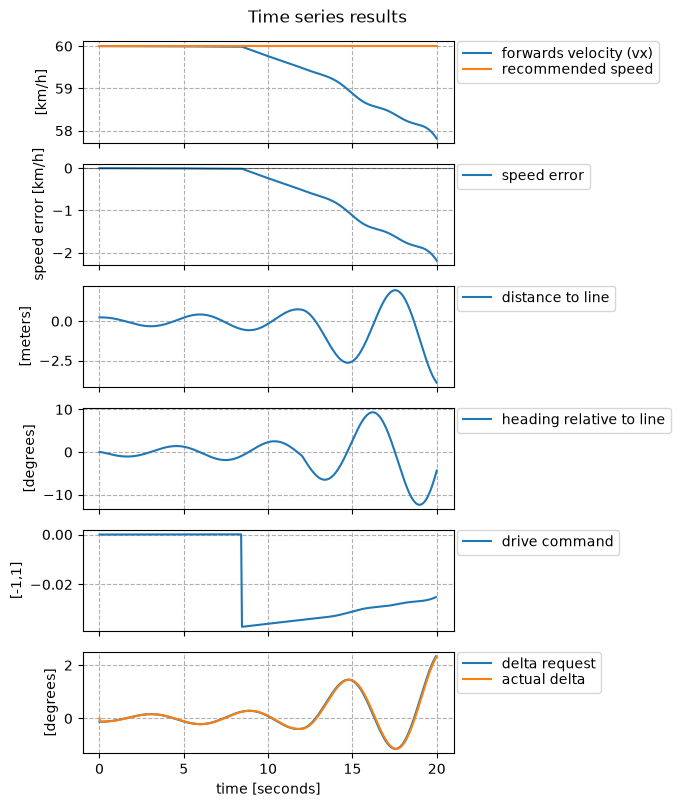

In [49]:
concerning_rollout_index = concerning_identity[1]
matching_plot_samples = [
    sample
    for rollout_index, sample in enumerate(metrics_sweep.samples())
    if rollout_index == concerning_rollout_index
]
if len(matching_plot_samples) != 1:
    raise RuntimeError(
        "concerning rollout index must match exactly one sweep sample"
    )
concerning_plot_sample = matching_plot_samples[0]
if any(
    concerning_plot_sample.values[parameter.name]
    != concerning_rollout_index_row[parameter.name]
    for parameter in METRICS_UNCERTAINTY_PARAMETERS
):
    raise RuntimeError(
        "concerning rollout metadata does not match the sweep sample"
    )
concerning_plot_kwargs, concerning_plot_post_create = (
    concerning_plot_sample.apply_to_env_kwargs(
        METRICS_SWEEP_ENVIRONMENT_KWARGS
    )
)
concerning_plot_environment = gymnasium.make(
    "dreamgym/autonomous_driving_env",
    **concerning_plot_kwargs,
)
concerning_figure_numbers_before = set(plt.get_fignums())
concerning_figures = {}
concerning_figure_paths = {}
try:
    concerning_figures = plot_simulation_results(
        concerning_plot_environment,
        concerning_time_series,
        should_plot_reward=False,
        should_plot_speed_error=True,
    )
    for figure_name, figure in concerning_figures.items():
        concerning_figure_paths[figure_name] = save_figure(
            figure,
            OUTPUT_ROOT / ("concerning_case_" + figure_name + ".png"),
        )
    plt.show()
finally:
    concerning_plot_environment.close()
    for figure_number in (
        set(plt.get_fignums()) - concerning_figure_numbers_before
    ):
        plt.close(figure_number)


## 4. Generate results tables

This cell uses the Gymnasium's built-in function `save_metric_tables` to generate tables that can (hopefully!) be easily inserted into a log-book.

In [50]:
EXPECTED_METRIC_TABLE_KEYS = {
    "aggregate_csv",
    "rollout_index_csv",
    "per_rollout_csv",
    "aggregate_markdown",
    "aggregate_latex",
}
metric_table_paths = save_metric_tables(
    metrics_results,
    OUTPUT_ROOT,
    file_prefix="performance_metrics",
    metrics=metrics,
)
if set(metric_table_paths) != EXPECTED_METRIC_TABLE_KEYS:
    raise RuntimeError("metric table export set is incomplete")
metric_plot_figure_numbers_before = set(plt.get_fignums())
try:
    metric_plot_paths = save_performance_metric_plots(
        histogram_results,
        OUTPUT_ROOT,
        metric_names=metrics.names(),
    )
finally:
    for figure_number in (
        set(plt.get_fignums()) - metric_plot_figure_numbers_before
    ):
        plt.close(figure_number)
exported_paths = (*metric_table_paths.values(), *metric_plot_paths.values())
if not all(
    Path(path).resolve().is_relative_to(OUTPUT_ROOT.resolve())
    for path in exported_paths
):
    raise RuntimeError("metric artifacts must stay below OUTPUT_ROOT")
print(metric_table_paths)
print(metric_plot_paths)
print(
    "These generated artifacts are contained below OUTPUT_ROOT. "
    "The CSV, Markdown, LaTeX, and plot files are not a reloadable "
    "evaluation bundle."
)


{'aggregate_csv': PosixPath('notebook_outputs/performance-metrics-and-uncertainty/performance_metrics_aggregate.csv'), 'rollout_index_csv': PosixPath('notebook_outputs/performance-metrics-and-uncertainty/performance_metrics_rollout_index.csv'), 'aggregate_markdown': PosixPath('notebook_outputs/performance-metrics-and-uncertainty/performance_metrics_aggregate.md'), 'aggregate_latex': PosixPath('notebook_outputs/performance-metrics-and-uncertainty/performance_metrics_aggregate.tex'), 'per_rollout_csv': PosixPath('notebook_outputs/performance-metrics-and-uncertainty/performance_metrics_per_rollout.csv')}
{'mean_abs_lateral_error_m_bar': PosixPath('notebook_outputs/performance-metrics-and-uncertainty/mean_abs_lateral_error_m_bar.png'), 'mean_abs_lateral_error_m_histogram': PosixPath('notebook_outputs/performance-metrics-and-uncertainty/mean_abs_lateral_error_m_histogram.png'), 'mean_abs_speed_error_to_recommended_kph_bar': PosixPath('notebook_outputs/performance-metrics-and-uncertainty/mea